In [ ]:
# Supervised Machine Learning- Regression and Classification
# Unsupervised ML - Clustering and recommendation system
# Re-inforcement Learning -

In [1]:
import os
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv('/content/diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.isnull().sum().sum()

np.int64(0)

In [4]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [9]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,27.334635,94.652344,32.450911,0.471876,33.240885,0.348958
std,3.369578,30.438286,12.096642,9.229014,105.547598,6.875366,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,23.000000,30.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,31.250000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [4]:
df['Glucose'] = np.where(df['Glucose']==0, df['Glucose'].median(), df['Glucose'])
df['BloodPressure'] = np.where(df['BloodPressure']==0, df['BloodPressure'].median(), df['BloodPressure'])
df['SkinThickness'] = np.where(df['SkinThickness']==0, df['SkinThickness'].median(), df['SkinThickness'])
df['Insulin'] = np.where(df['Insulin']==0, df['Insulin'].median(), df['Insulin'])
df['BMI'] = np.where(df['BMI']==0, df['BMI'].median(), df['BMI'])

In [5]:
train_data = df.sample(frac=0.80, random_state=1).reset_index(drop=True)
test_data = df.drop(train_data.index).reset_index(drop=True)
print("Data for Modeling - training " + str(train_data.shape))
print("Data for Predictions - test " + str(test_data.shape))


Data for Modeling - training (614, 9)
Data for Predictions - test (154, 9)


# Machine Learning Automation method - Traditional approach

## PYCARET

In [8]:
#!pip install pycaret==3.3.2

In [7]:
!python3 --version

Python 3.11.13


In [6]:
from pycaret.classification import *
# select * from abc

In [9]:
classification_model = setup(data=train_data, target="Outcome", session_id=123)

,Description,Value
0,Session id,123
1,Target,Outcome
2,Target type,Binary
3,Original data shape,"(614, 9)"
4,Transformed data shape,"(614, 9)"
5,Transformed train set shape,"(429, 9)"
6,Transformed test set shape,"(185, 9)"
7,Numeric features,8
8,Preprocess,True
9,Imputation type,simple


In [10]:
compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
ridge,Ridge Classifier,0.7601,0.8187,0.5381,0.6943,0.6048,0.4369,0.4450,0.0200
lda,Linear Discriminant Analysis,0.7578,0.8191,0.5381,0.6897,0.6033,0.4329,0.4405,0.0190
lr,Logistic Regression,0.7554,0.8174,0.5314,0.6872,0.5982,0.4266,0.4346,0.6070
et,Extra Trees Classifier,0.7458,0.8141,0.5229,0.6719,0.5811,0.4042,0.4146,0.1500
qda,Quadratic Discriminant Analysis,0.7367,0.7920,0.5243,0.6438,0.5736,0.3874,0.3941,0.0190
knn,K Neighbors Classifier,0.7296,0.7433,0.5643,0.6353,0.5872,0.3885,0.3976,0.0340
nb,Naive Bayes,0.7273,0.7942,0.5500,0.6293,0.5781,0.3794,0.3870,0.0190
rf,Random Forest Classifier,0.7249,0.7926,0.5305,0.6247,0.5645,0.3681,0.3755,0.1740
ada,Ada Boost Classifier,0.7179,0.7668,0.5167,0.6163,0.5555,0.3521,0.3594,0.0900
gbc,Gradient Boosting Classifier,0.7110,0.7755,0.5100,0.6076,0.5491,0.3390,0.3455,0.1350


Processing:   0%|          | 0/65 [00:00<?, ?it/s]

RidgeClassifier(alpha=1.0, class_weight=None, copy_X=True, fit_intercept=True,
                max_iter=None, positive=False, random_state=123, solver='auto',
                tol=0.0001)

In [11]:
ridge = create_model('ridge')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7674,0.8095,0.6000,0.6923,0.6429,0.4717,0.4744
1,0.7442,0.7714,0.5333,0.6667,0.5926,0.4095,0.4149
2,0.7907,0.8143,0.6000,0.7500,0.6667,0.5169,0.5237
3,0.7209,0.7810,0.4667,0.6364,0.5385,0.3452,0.3537
4,0.7907,0.8476,0.5333,0.8000,0.6400,0.5006,0.5211
5,0.6512,0.7976,0.3333,0.5000,0.4000,0.1677,0.1746
6,0.7442,0.7929,0.6000,0.6429,0.6207,0.4281,0.4286
7,0.7442,0.8054,0.5000,0.6364,0.5600,0.3833,0.3889
8,0.8140,0.8867,0.5714,0.8000,0.6667,0.5426,0.5573


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

In [13]:
# HyperParameter Tuning
ridge_tuned = tune_model(ridge)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7674,0.8095,0.6000,0.6923,0.6429,0.4717,0.4744
1,0.7442,0.7714,0.5333,0.6667,0.5926,0.4095,0.4149
2,0.7907,0.8119,0.6000,0.7500,0.6667,0.5169,0.5237
3,0.7209,0.7786,0.4667,0.6364,0.5385,0.3452,0.3537
4,0.7907,0.8524,0.5333,0.8000,0.6400,0.5006,0.5211
5,0.6512,0.7976,0.3333,0.5000,0.4000,0.1677,0.1746
6,0.7442,0.7929,0.6000,0.6429,0.6207,0.4281,0.4286
7,0.7442,0.8079,0.5000,0.6364,0.5600,0.3833,0.3889
8,0.8140,0.8842,0.5714,0.8000,0.6667,0.5426,0.5573


Processing:   0%|          | 0/7 [00:00<?, ?it/s]

Fitting 10 folds for each of 10 candidates, totalling 100 fits


Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


In [14]:
evaluate_model(ridge)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

from matplotlib import pyplot as plt
import seaborn as sns
_df_0.groupby('Parameters').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

In [15]:
# prediction
predict_model(ridge)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Ridge Classifier,0.8000,0.7514,0.5938,0.7755,0.6726,0.5322,0.5421


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,prediction_label
466,1,117.0,60.0,23.0,106.0,33.799999,0.466,27,0,0
536,1,91.0,64.0,24.0,30.5,29.200001,0.192,21,0,0
84,1,81.0,74.0,41.0,57.0,46.299999,1.096,32,0,0
253,12,84.0,72.0,31.0,30.5,29.700001,0.297,46,1,0
140,1,199.0,76.0,43.0,30.5,42.900002,1.394,22,1,1
...,...,...,...,...,...,...,...,...,...,...
91,1,103.0,80.0,11.0,82.0,19.400000,0.491,22,0,0
545,2,117.0,90.0,19.0,71.0,25.200001,0.313,21,0,0
554,6,123.0,72.0,45.0,230.0,33.599998,0.733,34,0,0
3,3,61.0,82.0,28.0,30.5,34.400002,0.243,46,0,0


In [16]:
save_model(ridge, 'ridge_model')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Pregnancies', 'Glucose',
                                              'BloodPressure', 'SkinThickness',
                                              'Insulin', 'BMI',
                                              'DiabetesPedigreeFunction',
                                              'Age'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=None,
                                                               keep_empty_features=False,
                                                               missing_values=nan,
                                                               strategy='mean'))),
                 (...
          

# Clustering - Grouping

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

In [18]:
X, y = make_blobs(n_samples=1000, centers=5, random_state=42)

In [20]:
pd.DataFrame(X)

,0,1
0,5.020077,2.583755
1,3.232367,1.195353
2,-6.107928,-9.728652
3,5.199669,3.053950
4,1.380819,4.593374
...,...,...
995,-4.633093,8.488531
996,3.291693,2.716434
997,-9.447840,7.136552
998,4.604890,3.743970


In [21]:
y

array([1, 1, 2, 1, 4, 2, 3, 4, 1, 4, 4, 2, 3, 2, 3, 2, 0, 3, 0, 4, 1, 0,
       3, 2, 0, 1, 0, 3, 4, 3, 1, 3, 4, 3, 0, 2, 4, 4, 4, 0, 4, 3, 3, 2,
       3, 2, 1, 1, 0, 2, 1, 3, 2, 0, 0, 0, 0, 2, 2, 0, 1, 3, 2, 4, 2, 1,
       3, 3, 1, 1, 3, 2, 1, 2, 3, 0, 3, 1, 1, 3, 0, 1, 2, 2, 3, 1, 0, 4,
       0, 3, 1, 3, 1, 4, 4, 2, 0, 0, 2, 3, 2, 4, 1, 2, 0, 1, 0, 2, 4, 0,
       0, 1, 2, 2, 3, 0, 3, 2, 0, 4, 2, 0, 2, 2, 2, 2, 3, 2, 0, 1, 1, 3,
       1, 4, 2, 4, 1, 4, 0, 3, 2, 0, 1, 0, 1, 1, 2, 1, 1, 4, 3, 2, 1, 1,
       0, 1, 1, 0, 3, 1, 3, 1, 3, 0, 3, 1, 4, 3, 0, 1, 2, 0, 0, 2, 4, 2,
       3, 2, 1, 4, 1, 0, 1, 3, 4, 4, 1, 2, 3, 0, 3, 0, 1, 4, 1, 0, 4, 2,
       0, 1, 2, 3, 2, 2, 3, 4, 4, 0, 4, 1, 0, 3, 3, 4, 1, 2, 2, 2, 3, 4,
       2, 2, 0, 2, 0, 4, 2, 4, 1, 1, 0, 1, 0, 1, 1, 3, 0, 0, 3, 1, 4, 3,
       2, 4, 2, 2, 2, 2, 3, 4, 2, 2, 4, 1, 4, 0, 3, 1, 1, 0, 1, 4, 1, 3,
       1, 3, 3, 3, 2, 2, 1, 1, 3, 4, 0, 4, 2, 0, 3, 4, 4, 2, 1, 4, 2, 3,
       1, 1, 1, 0, 4, 0, 3, 4, 1, 3, 4, 4, 0, 4, 3,

In [22]:
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(X)

KMeans(algorithm='lloyd', copy_x=True, init='k-means++', max_iter=300,
       n_clusters=5, n_init='auto', random_state=42, tol=0.0001, verbose=0)

In [23]:
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

In [24]:
labels

array([4, 4, 0, 4, 1, 0, 3, 1, 4, 1, 1, 0, 3, 0, 3, 0, 2, 3, 2, 1, 4, 2,
       3, 0, 2, 1, 2, 3, 1, 3, 4, 3, 1, 3, 2, 0, 1, 1, 1, 2, 1, 3, 3, 0,
       3, 0, 1, 4, 2, 0, 4, 3, 0, 2, 2, 2, 2, 0, 0, 2, 4, 3, 0, 1, 0, 4,
       3, 3, 4, 4, 3, 0, 4, 0, 3, 2, 3, 4, 1, 3, 2, 4, 0, 0, 3, 4, 2, 1,
       2, 3, 4, 3, 4, 1, 1, 0, 2, 2, 0, 3, 0, 1, 4, 0, 2, 4, 2, 0, 1, 2,
       2, 4, 0, 0, 3, 2, 3, 0, 2, 2, 0, 2, 0, 0, 0, 0, 3, 0, 2, 4, 4, 3,
       4, 1, 0, 1, 4, 1, 2, 3, 0, 2, 4, 2, 4, 4, 0, 4, 4, 1, 3, 0, 4, 4,
       2, 4, 4, 2, 3, 4, 3, 1, 3, 2, 3, 1, 1, 3, 2, 4, 0, 2, 2, 0, 1, 0,
       3, 0, 4, 1, 4, 2, 4, 3, 1, 1, 4, 0, 3, 2, 3, 2, 4, 1, 4, 2, 1, 0,
       2, 4, 0, 3, 0, 0, 3, 1, 1, 2, 1, 4, 2, 3, 3, 1, 4, 0, 0, 0, 3, 1,
       0, 0, 2, 0, 2, 1, 0, 1, 4, 4, 2, 4, 2, 4, 4, 3, 2, 2, 3, 4, 1, 3,
       0, 1, 0, 0, 0, 0, 3, 1, 0, 0, 1, 4, 1, 2, 3, 4, 4, 2, 4, 1, 4, 3,
       4, 3, 3, 3, 0, 0, 4, 4, 3, 1, 2, 1, 0, 2, 3, 1, 1, 0, 4, 1, 0, 3,
       4, 4, 4, 2, 1, 2, 3, 1, 4, 3, 1, 1, 2, 4, 3,

In [25]:
centroids

array([[-6.68630691, -6.81139455],
       [ 2.03639615,  4.26762858],
       [-2.50265159,  9.03963769],
       [-8.80798056,  7.40425704],
       [ 4.66534309,  1.87476184]])

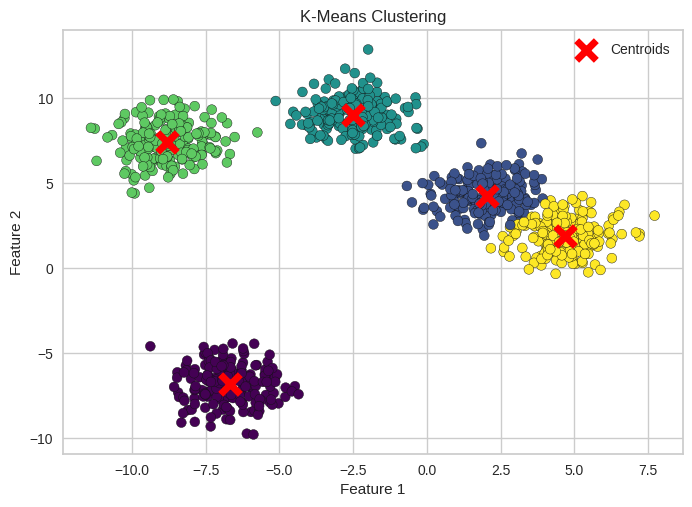

In [26]:
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50, edgecolors='k')
plt.scatter(centroids[:, 0], centroids[:, 1], c ='red', marker='x', s=200, linewidths=5, label="Centroids")
plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()